# TUH preprocessing analysis — is the LaBraM protocol right for TUEG and TUAB?

LaBraM, BIOT and CBraMod prepare TUAB with one fixed recipe: keep 23 referential channels,
band-pass 0.1–75 Hz, **notch 50 Hz**, resample to 200 Hz, express in µV
(`dataset_maker/make_TUAB.py`, walked through step by step in
`notebooks/tuab_data_preparation.ipynb`). TUH is recorded in the US, where mains power is
**60 Hz**, and the full TUEG corpus mixes sampling rates (250–1000 Hz), equipment and two
decades of recordings. Before converting 1.76 TB of TUEG this notebook measures, on a
stratified sample of real recordings, what the protocol leaves in the signal and whether
any of it could act as a shortcut for brain age.

**Contents.** 1 The protocol and the variants tested · 2 The sample · 3 Measures ·
4 Mains interference in the raw recordings · 5 What each protocol leaves at the model input ·
6 Is the residual a bias? · 7 Amplitude scale and signal integrity ·
8 Removing the line without a hole · 9 Conclusions and the recommended TUH protocol.

The measurements come from `labram/eval/preprocessing_qc.py` (`analyze_recording`), run on a
120 s segment (60–180 s after the start) of each recording.

In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

from labram.eval import preprocessing_qc as qc
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

Q = "/data/datasets/EEG-public/TUH_EEG/qc_sample"
TUAB_EDF = "/data/datasets/EEG-public/TUH_EEG/tuab/v3.0.1/edf"
sample = pd.read_parquet(f"{Q}/sample.parquet")


def edf_path(row):
    return f"{Q}/tueg/{row['path']}" if row["group"] == "TUEG" else f"{TUAB_EDF}/{row['path']}"


table, spectra = qc.analyze_sample(sample.to_dict("records"), edf_path,
                                   cache=f"{Q}/qc_results.pkl", workers=7)
df = table.merge(sample[["stem", "group", "sfreq", "year", "age", "sex", "abnormal", "montage"]],
                 on="stem")
df["sfreq"] = df["sfreq"].astype(int)          # native rates are whole Hz
df["recording year"] = pd.cut(df["year"], [1990, 2004, 2010, 2025], labels=["≤2004", "2005–10", "2011+"])
L, N60, BOTH, LP45 = (p.name for p in qc.PROTOCOLS)
plt.rcParams.update({"figure.dpi": 110})
print(f"{len(df)} recordings analysed, {df.get('error', pd.Series(dtype=str)).notna().sum()} errors")

187 recordings analysed, 0 errors


## 1. The protocol and the variants tested

For a channel $x(t)$ in µV sampled at $f_s$ Hz, the LaBraM protocol computes

$$
y = \operatorname{resample}_{200\,\mathrm{Hz}}\Big(\operatorname{notch}_{50}\big(\operatorname{bp}_{[0.1,\,75]}(x)\big)\Big)
\tag{1.1}
$$

where $\operatorname{bp}_{[0.1,75]}$ is MNE's zero-phase FIR band-pass (`raw.filter(0.1, 75)`,
transition bands chosen automatically: 0.1 Hz below, $\min(\max(0.25\cdot75, 2), f_s/2-75)$ Hz
above), $\operatorname{notch}_{f_0}$ is MNE's FIR notch at $f_0$ Hz (`raw.notch_filter(f0)`),
and $\operatorname{resample}_{200}$ is MNE's FFT resampler (`raw.resample(200)`).
Table 1.1 lists the variants measured next to it; each changes only the notch or the low-pass
of Eq. (1.1) (`labram/eval/preprocessing_qc.py::PROTOCOLS`).

### Table 1.1. Protocol variants

One row per variant: notch frequencies (Hz), band-pass edges (Hz), output rate (Hz).

In [2]:
t11 = pd.DataFrame([{"protocol": p.name, "notch (Hz)": ", ".join(f"{f:g}" for f in p.notch),
                     "band-pass (Hz)": f"{p.l_freq:g}–{p.h_freq:g}", "output rate (Hz)": p.sfreq}
                    for p in qc.PROTOCOLS]).set_index("protocol")
numbered_table(t11, "1.1", "Protocol variants")

,notch (Hz),band-pass (Hz),output rate (Hz)
protocol,,,
labram (50 Hz notch),50,0.1–75,200.00
60 Hz notch,60,0.1–75,200.00
50 + 60 Hz notch,"50, 60",0.1–75,200.00
"60 Hz notch, 45 Hz low-pass",60,0.1–45,200.00


## 2. The sample

TUEG recordings were drawn from the corpus index (`dataset_maker/tuh_index.py`), restricted to
recordings with all 23 channels, a known age and at least 5 minutes, **one recording per
patient**, up to 12 per cell of native sampling rate × recording year. TUAB adds 40 normal and
40 abnormal recordings (one per patient). Table 2.1 gives the counts.

The recording year is the year in the EDF header's `Startdate` field (the date the EEG was
recorded, not the patient's age), grouped as ≤2004, 2005–10 and 2011+. Sampling rate and
recording year are not independent in TUEG: 400 Hz is almost only ≤2004, 512 Hz and
1000 Hz almost only 2011+, and 256 Hz never appears in 2005–10 (empty cells in Table 2.1). Any
property of the equipment therefore also carries the recording date — and through it, as
Section 6 shows, the patient's age.

### Table 2.1. Sample composition

Recordings per group × native sampling rate (Hz) × recording year (from the EDF header).

In [3]:
t21 = df.pivot_table(index=["group", "sfreq"], columns="recording year", values="stem", aggfunc="count",
                     observed=False).fillna(0).astype(int)
t21["total"] = t21.sum(axis=1)
numbered_table(t21, "2.1", "Sample composition", precision=0)

Table 2.2 shows the EDF header fields that could say how a recording was already filtered or
scaled: the physical unit of the 23 channels and the free-text *prefiltering* field. Every
recording is in µV, and the prefiltering field carries no information (`HP:0 LP:0 N:0`, or `-1`
placeholders) — the headers cannot tell us whether a hardware notch was applied, so mains
interference has to be measured in the signal itself (Section 4).

### Table 2.2. EDF header unit and prefiltering fields

Recordings per (unit, prefiltering text, group).

In [4]:
t22 = df.groupby(["units", "prefilter", "group"]).size().unstack(fill_value=0)
numbered_table(t22, "2.2", "EDF header unit and prefiltering fields", precision=0)

## 3. Measures

**Spectrum.** For a segment $x_c(t)$, $c = 1..C$ channels, the channel-median power spectral
density is

$$
P(f) = \operatorname{median}_{c}\ \operatorname{Welch}\big(x_c\big)(f)
\qquad [\mu\mathrm{V}^2/\mathrm{Hz}]
\tag{3.1}
$$

with 4 s Hann segments and 50% overlap (0.25 Hz resolution;
`preprocessing_qc.py::channel_median_psd`). The median over channels keeps one bad electrode
from dominating.

**Line-noise prominence.** How far a narrow band around $f_0$ stands above its neighbourhood:

$$
\mathrm{LNP}(f_0) = 10\log_{10}\frac{\operatorname{mean}_{|f-f_0|\le 0.5} P(f)}
{\operatorname{median}_{2\le |f-f_0| \le 5} P(f)} \qquad [\mathrm{dB}]
\tag{3.2}
$$

(`line_prominence_db`). $\mathrm{LNP}\approx 0$ dB means no line; 10 dB means a line ten times
its surroundings; a negative value is a dip, e.g. the hole a notch filter cuts. It is measured
at the mains fundamentals (50, 60 Hz), the 2nd/3rd US harmonics (120, 180 Hz), and where
harmonics would fold back by aliasing: 180 Hz sampled at 250 or 256 Hz lands at 70 or 76 Hz,
and after resampling to 200 Hz, 120 Hz lands at 80 Hz and 180 Hz at 20 Hz.

**Mains share of the output.** The share of the 0.5–75 Hz power that falls within ±5 Hz of 60 Hz:

$$
F_{55\text{–}65} = \frac{\sum_{55\le f\le 65} P(f)}{\sum_{0.5\le f\le 75} P(f)}
\tag{3.3}
$$

(`band_fraction`).

**Amplitude and integrity** (`amplitude_stats`, on the raw 23-channel segment in µV, $T$ samples):

$$
A_{50} = \operatorname{median}_{c,t} |x_c(t)|,\qquad A_{99} = \operatorname{quantile}_{0.99,\,c,t} |x_c(t)|
\qquad [\mu\mathrm{V}]
\tag{3.4}
$$

$$
\mathrm{clip} = \frac{1}{CT}\sum_{c,t} \mathbb{1}\big[|x_c(t)| \ge 0.995\, x_{\max}\big]
\tag{3.5}
$$

where $x_{\max}$ is the EDF physical maximum (±5000 µV for TUH), and

$$
\mathrm{flat} = \frac{1}{C}\sum_c \mathbb{1}\Big[\min_k \operatorname{std}\big(x_c[\text{10 s window } k]\big) < 0.5\,\mu\mathrm{V}\Big]
\tag{3.6}
$$

is the share of channels that are flat (disconnected or saturated) in some 10 s window.

## 4. Mains interference in the raw recordings

Figure 4.1 averages $\log_{10} P(f)$ of Eq. (3.1) over the recordings of each sampling-rate
group, 40–130 Hz (up to each group's Nyquist frequency). Table 4.1 gives the median
$\mathrm{LNP}$ of Eq. (3.2) per group and the share of recordings with a clear line
($\mathrm{LNP}_{60} > 6$ dB, a 4× peak).

### Figure 4.1. Raw spectrum around the mains frequencies (before any filtering)

(a) TUEG and (b) TUAB: mean over recordings of $\log_{10} P(f)$ (µV²/Hz, Eq. 3.1) of the raw
120 s segment **before any filtering** (native sampling rate, no band-pass, no notch), one line
per native sampling rate; dashed lines at 50 and 60 Hz. $n$ per line in Table 2.1. The curves are
*means* of log-spectra, so a minority of recordings with strong lines produces a visible peak even
where the *median* recording has almost none (Table 4.1).

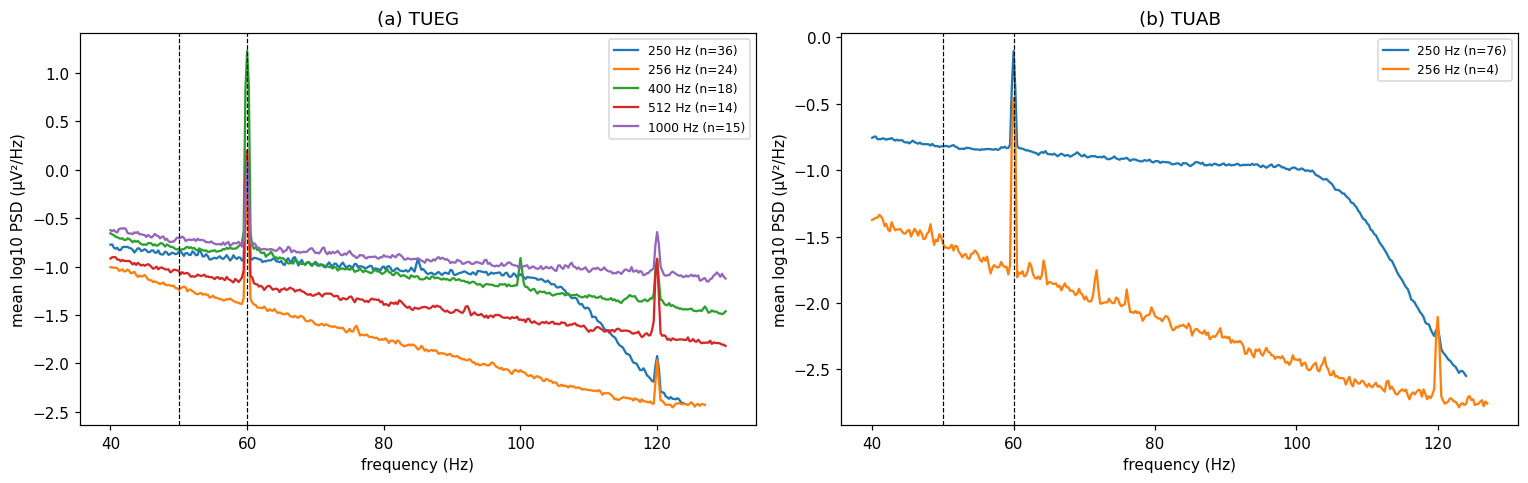

In [5]:
def mean_log_psd(stems, key, fmin, fmax):
    curves = []
    for s in stems:
        f, p = spectra[s][key]
        m = (f >= fmin) & (f <= fmax)
        curves.append((f[m], np.log10(p[m])))
    n = min(len(c[0]) for c in curves)
    return curves[0][0][:n], np.mean([c[1][:n] for c in curves], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, group in zip(axes, ["TUEG", "TUAB"]):
    for sf, g in df[df.group == group].groupby("sfreq"):
        f, y = mean_log_psd(g.stem, "raw_psd", 40, min(130, sf / 2 - 1))
        ax.plot(f, y, label=f"{sf:g} Hz (n={len(g)})")
    for f0 in (50, 60):
        ax.axvline(f0, color="k", ls="--", lw=0.8)
    ax.set(title=group, xlabel="frequency (Hz)", ylabel="mean log10 PSD (µV²/Hz)")
    ax.legend(fontsize=8)
panel_labels(axes)
assert_max_columns(fig)
plt.tight_layout(); plt.show()

### Table 4.1. Line-noise prominence of the raw recordings (before any filtering)

Median $\mathrm{LNP}$ (dB, Eq. 3.2) of the unfiltered recordings at each probe frequency per group × native sampling rate; `Hz` = native sampling rate; `60 p75`/`60 p90` = 75th/90th percentile of $\mathrm{LNP}_{60}$; `%>6dB` / `%>20dB` = percentage of recordings with $\mathrm{LNP}_{60}$ above 6 / 20 dB; `n` recordings. – where the frequency is above the group's Nyquist limit (half the sampling rate).

In [6]:
raw_cols = {f"raw_lnp_{f}": f"{f} Hz" for f in (50, 60, 120, 180, 70, 76)}
g41 = df.groupby(["group", "sfreq"])
t41 = g41[list(raw_cols)].median().rename(columns=raw_cols)
t41["60 p75"] = g41["raw_lnp_60"].quantile(0.75)
t41["60 p90"] = g41["raw_lnp_60"].quantile(0.90)
t41["%>6dB"] = 100 * g41["raw_lnp_60"].apply(lambda s: (s > 6).mean())
t41["%>20dB"] = 100 * g41["raw_lnp_60"].apply(lambda s: (s > 20).mean())
t41["n"] = g41.size()
t41.index.names = ["group", "Hz"]
numbered_table(t41, "4.1", "Line-noise prominence of the raw recordings", precision=1).format(
    "{:.0f}", subset=["%>6dB", "%>20dB", "n"])

Table 4.1 and Figure 4.1 give the first answer. **There is no 50 Hz line anywhere** (median
$\mathrm{LNP}_{50}\approx 0$ dB in every group), so the protocol's 50 Hz notch removes no
interference — it only cuts a hole in genuine EEG at 50 Hz (Section 5). **A 60 Hz line is
present in about half of the recordings** (`%>6dB` per group in Table 4.1; over the whole
sample, a third exceed 6 dB), and its strength depends on the equipment: weakest in TUAB and in
TUEG's 1000 Hz recordings, strongest in the 400 Hz group (the ≤2004 systems of Table 2.1). The 120 Hz and 180 Hz harmonics are visible where the sampling rate allows
them (above 240 / 360 Hz native). The
acquisition-alias probes (70, 76 Hz) are flat: the 180 Hz harmonic is not folded into the band.

## 5. What each protocol leaves at the model input

Every recording was passed through the four protocols of Table 1.1 and Eqs. (3.2)–(3.3) were
measured on the 200 Hz output. Figure 5.1 compares the output spectra of the LaBraM protocol and
the 60 Hz-notch variant; Table 5.1 summarises all four.

### Figure 5.1. Model-input spectrum around 60 Hz after processing, LaBraM vs 60 Hz notch

Mean over recordings of $\log_{10} P(f)$ (µV²/Hz, Eq. 3.1) of the 200 Hz output **after
processing**, 40–90 Hz, one line per native sampling rate. Left column: LaBraM protocol (50 Hz
notch); right column: the same with a 60 Hz notch instead. (a, b) TUEG ($n$ = 107), (c, d) TUAB
($n$ = 80). Dashed lines at 50, 60 and 75 Hz (low-pass edge).

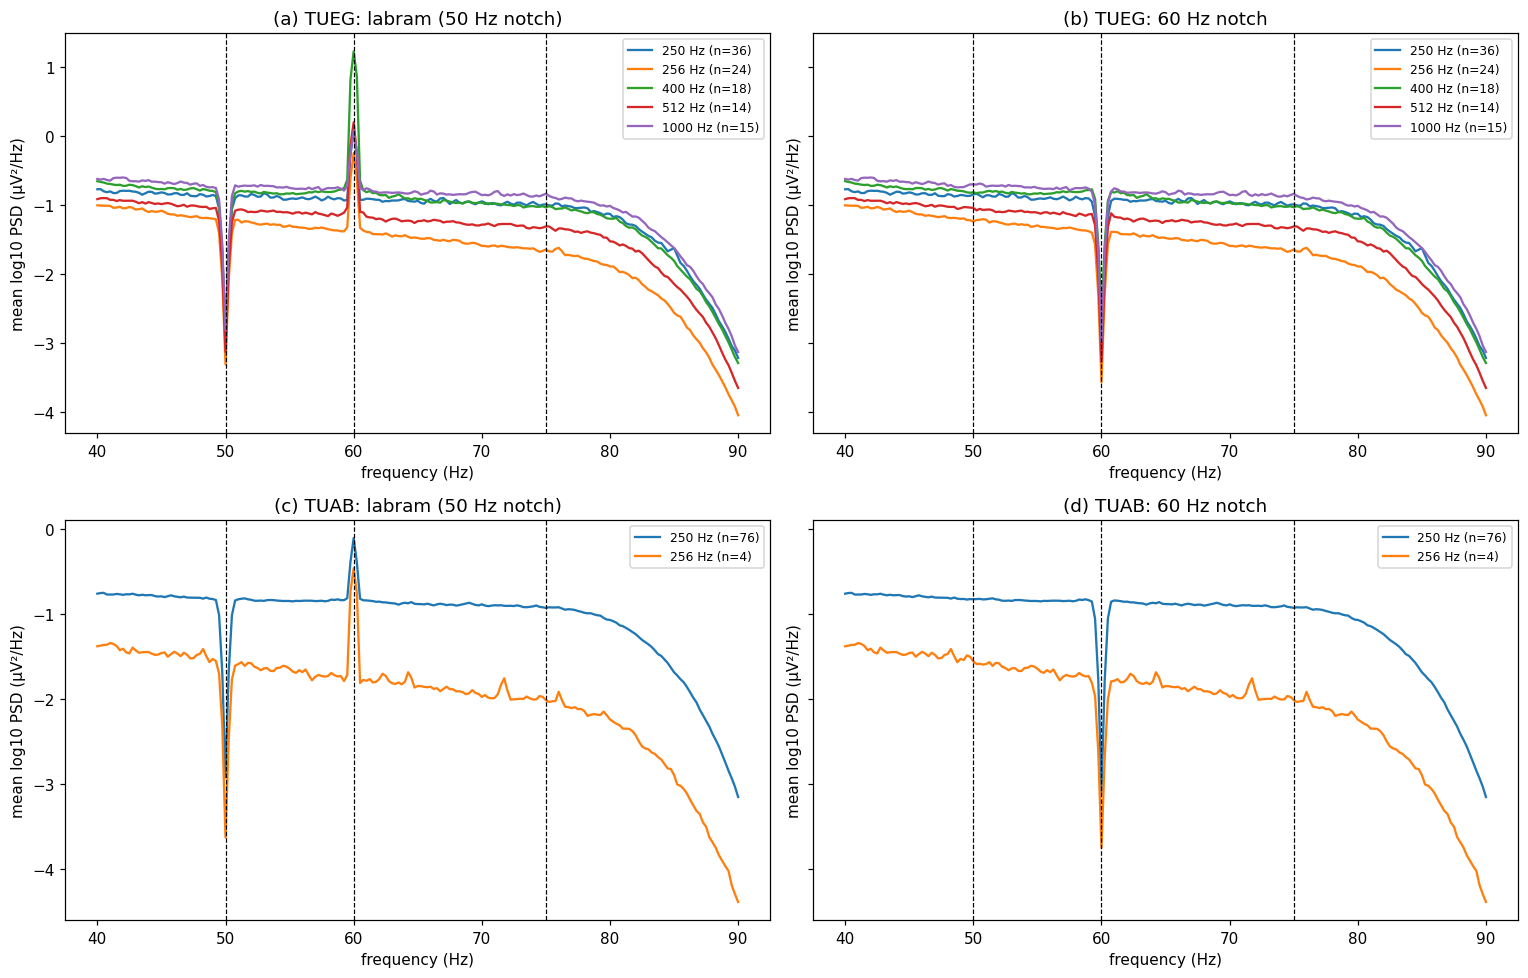

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey="row")
eg = df[df.group == "TUEG"]
for row, group in enumerate(["TUEG", "TUAB"]):
    for ax, proto in zip(axes[row], [L, N60]):
        for sf, g in df[df.group == group].groupby("sfreq"):
            f, y = mean_log_psd(g.stem, f"{proto}|psd", 40, 90)
            ax.plot(f, y, label=f"{sf:g} Hz (n={len(g)})")
        for f0 in (50, 60, 75):
            ax.axvline(f0, color="k", ls="--", lw=0.8)
        ax.set(title=f"{group}: {proto}", xlabel="frequency (Hz)", ylabel="mean log10 PSD (µV²/Hz)")
        ax.legend(fontsize=8)
panel_labels(axes)
assert_max_columns(fig)
plt.tight_layout(); plt.show()

### Table 5.1. Line noise left at the model input after processing, per protocol

TUEG + TUAB, all 187 recordings, after processing: median $\mathrm{LNP}$ (dB, Eq. 3.2) at 50 and 60 Hz and at the resampling-alias probes 20 and 80 Hz; `share60>6dB` = share of recordings with a 60 Hz line above 6 dB left; `F55-65` = median mains share of the output power (Eq. 3.3, %).

In [8]:
rows = []
for p in qc.PROTOCOLS:
    k = p.name
    rows.append({"protocol": k,
                 "50 Hz": df[f"{k}|lnp_50"].median(), "60 Hz": df[f"{k}|lnp_60"].median(),
                 "20 Hz (alias of 180)": df[f"{k}|lnp_20"].median(),
                 "80 Hz (alias of 120)": df[f"{k}|lnp_80"].median(),
                 "share60>6dB": (df[f"{k}|lnp_60"] > 6).mean(),
                 "F55-65 (%)": 100 * df[f"{k}|frac_55_65"].median()})
t51 = pd.DataFrame(rows).set_index("protocol")
numbered_table(t51, "5.1", "Line noise left at the model input", precision=2)

,50 Hz,60 Hz,20 Hz (alias of 180),80 Hz (alias of 120),share60>6dB,F55-65 (%)
protocol,,,,,,
labram (50 Hz notch),-5.05,3.13,0.05,0.46,0.33,1.39
60 Hz notch,0.04,-5.35,0.05,0.46,0.01,0.83
50 + 60 Hz notch,-5.05,-5.35,0.05,0.46,0.01,0.83
"60 Hz notch, 45 Hz low-pass",-0.42,-5.68,0.06,-0.99,0.01,0.00


Table 5.1 is the core result. The LaBraM protocol passes the 60 Hz line through unchanged
(its median $\mathrm{LNP}_{60}$ equals the raw value of Table 4.1) and cuts a dip at 50 Hz
where there was no interference. A 60 Hz notch removes the line in almost every recording
(median $\mathrm{LNP}_{60}$ becomes a dip of about −5 dB, the notch itself; `share60>6dB` drops
to about 1%, the few recordings whose line is wider than MNE's default notch width of
$f_0/200$ Hz). Notching both 50 and 60 Hz only adds the needless 50 Hz dip. Resampling causes no
systematic aliasing (median of the 20 and 80 Hz probes ≈0 dB): MNE's FIR low-pass at 75 Hz
attenuates 120/180 Hz before the 200 Hz resampler; the 80 Hz probe lies in the low-pass
transition band, where the little that remains is already strongly attenuated. A 45 Hz low-pass removes the mains band entirely but also discards 45–75 Hz
gamma/EMG content that the pre-trained LaBraM tokenizer was trained on.

## 6. Is the residual a bias?

A 60 Hz line matters for brain age only if its strength is related to age. Figure 6.1 plots the
raw $\mathrm{LNP}_{60}$ against age and by recording year; Table 6.1 gives Spearman correlations

$$
\rho_S(u, v) = \operatorname{corr}_{\text{Pearson}}\big(\operatorname{rank}(u), \operatorname{rank}(v)\big)
\tag{6.1}
$$

(`scipy.stats.spearmanr`, two-sided $p$), between $\mathrm{LNP}_{60}$ and age, and between age
and the native sampling rate, per group.

### Figure 6.1. 60 Hz line strength vs age and recording year

(a) Raw $\mathrm{LNP}_{60}$ (dB, Eq. 3.2) against age (years), TUEG (dots, colour = native
sampling rate) and TUAB (crosses); (b) raw $\mathrm{LNP}_{60}$ by recording year, TUEG. $n$ in
Table 2.1.

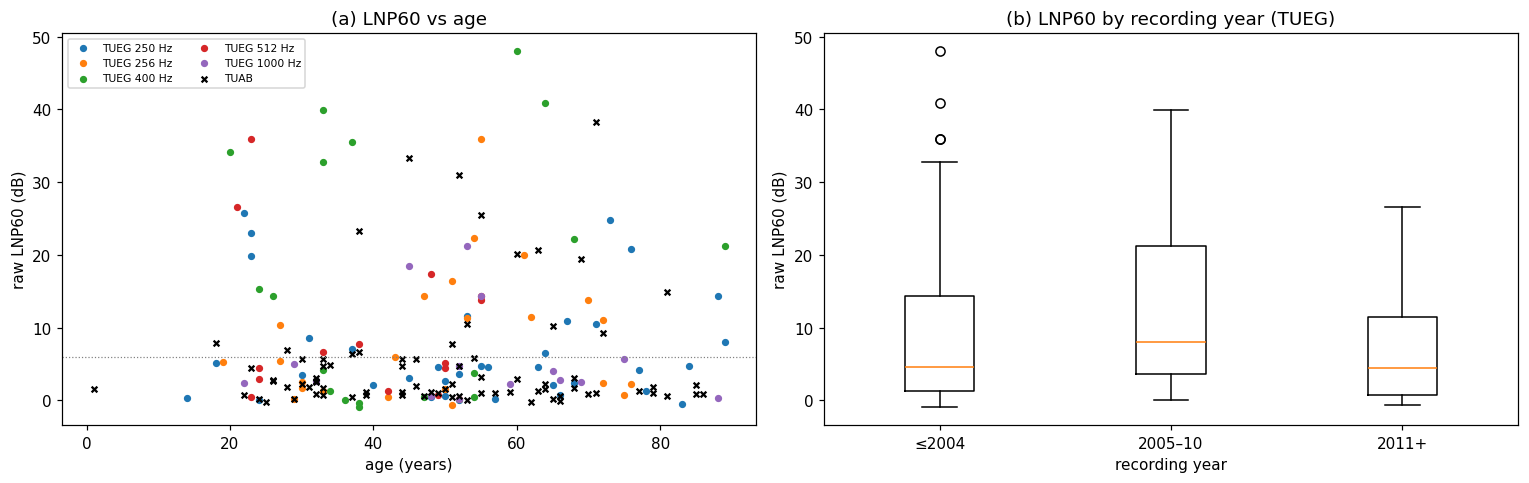

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
for sf, g in eg.groupby("sfreq"):
    ax.scatter(g.age, g.raw_lnp_60, s=14, label=f"TUEG {sf:g} Hz")
ab = df[df.group == "TUAB"]
ax.scatter(ab.age, ab.raw_lnp_60, marker="x", c="k", s=14, label="TUAB")
ax.axhline(6, color="grey", ls=":", lw=0.8)
ax.set(title="LNP60 vs age", xlabel="age (years)", ylabel="raw LNP60 (dB)")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
yg = eg["recording year"]
years = [e for e in yg.cat.categories if (yg == e).any()]
ax.boxplot([eg.loc[yg == e, "raw_lnp_60"] for e in years], tick_labels=years)
ax.set(title="LNP60 by recording year (TUEG)", xlabel="recording year", ylabel="raw LNP60 (dB)")
panel_labels(axes)
assert_max_columns(fig)
plt.tight_layout(); plt.show()

### Table 6.1. Correlation of line strength and equipment with age

Spearman $\rho_S$ (Eq. 6.1) and two-sided $p$ per group; `n` recordings.

In [10]:
rows = []
for group, g in df.groupby("group"):
    for name, u in [("raw LNP60", g.raw_lnp_60), ("native sampling rate", g.sfreq),
                    ("recording year", g.year)]:
        r, p = spearmanr(u, g.age, nan_policy="omit")
        rows.append({"group": group, "variable vs age": name, "rho_S": r, "p": p, "n": len(g)})
t61 = pd.DataFrame(rows).set_index(["group", "variable vs age"])
numbered_table(t61, "6.1", "Correlation of line strength and equipment with age", precision=3)

### Table 6.2. Patient age by equipment and recording year across the TUEG corpus

All TUEG recordings of the corpus index with a usable age (not only the sample): mean and median patient age (years) and `n` recordings per native sampling rate and per recording year.

In [11]:
IX = "/data/datasets/EEG-public/TUH_EEG/index"
index = pd.read_parquet(f"{IX}/tuh_index.parquet" if os.path.exists(f"{IX}/tuh_index.parquet")
                        else f"{IX}/tuh_index_partial.parquet")
tg = index[(index.source == "tueg") & index.age.notna() & index.sfreq.notna()].copy()
tg["sfreq"] = tg["sfreq"].astype(int)
tg["recording year"] = pd.cut(tg.year, [1990, 2004, 2010, 2025], labels=["≤2004", "2005–10", "2011+"])
t62 = pd.concat({"sampling rate (Hz)": tg.groupby("sfreq").age.agg(["mean", "median", "count"]),
                 "recording year": tg.groupby("recording year", observed=True).age.agg(["mean", "median", "count"])})
t62.columns = ["mean age", "median age", "n"]
numbered_table(t62[t62.n >= 100], "6.2", "Patient age by equipment and recording year across the TUEG corpus", precision=1)

Within the sample, line strength is **not** directly correlated with age (Table 6.1,
$\rho_S \approx 0$ in both groups): the 60 Hz line is not a recording-level age marker. The
risk is at group level. Table 6.2 shows on the whole corpus that patients recorded on different
equipment generations, and in different recording years, differ in mean age by several years — the 400 Hz
and 512 Hz systems and the ≤2004 recordings are the youngest — and Table 4.1 shows that the 400 Hz
(≤2004) systems also carry the strongest 60 Hz line. A model can pick up such equipment
fingerprints and use them as a proxy for the age mix of the sub-population they come from.
Removing the line (Table 5.1) cuts this path at no cost: brain-age models use no physiological
signal in a 1 Hz band at 60 Hz. Equipment and recording year should in any case be reported as strata of
the evaluation (error per sampling rate and recording year), since other fingerprints than the line remain.

## 7. Amplitude scale and signal integrity

Table 7.1 gives the amplitude and integrity measures of Eqs. (3.4)–(3.6) per group and, for
TUAB, per normal/abnormal label. Figure 7.1 plots $A_{50}$ against age and by sampling rate.

### Table 7.1. Amplitude and integrity of the raw signal

Medians over recordings of $A_{50}$, $A_{99}$ (µV, Eq. 3.4), clip share (Eq. 3.5) and flat-channel share (Eq. 3.6); `n` recordings.

In [12]:
df["cohort"] = np.where(df.group == "TUEG", "TUEG",
                        np.where(df.abnormal.fillna(0).astype(int) == 1, "TUAB abnormal", "TUAB normal"))
g71 = df.groupby("cohort")
t71 = g71[["median_abs_uv", "p99_abs_uv", "clip_frac", "flat_channel_frac"]].median()
t71.columns = ["A50 (µV)", "A99 (µV)", "clip", "flat"]
t71["n"] = g71.size()
numbered_table(t71, "7.1", "Amplitude and integrity of the raw signal", precision=3)

,A50 (µV),A99 (µV),clip,flat,n
cohort,,,,,
TUAB abnormal,9.915,77.476,0.000,0.000,40
TUAB normal,8.469,80.910,0.000,0.000,40
TUEG,15.262,124.515,0.000,0.000,107


### Figure 7.1. Signal amplitude vs age and sampling rate

(a) $A_{50}$ (µV, Eq. 3.4, log scale) against age (years) for TUEG (dots) and TUAB (crosses);
(b) $A_{50}$ by native sampling rate, TUEG. $n$ in Table 2.1.

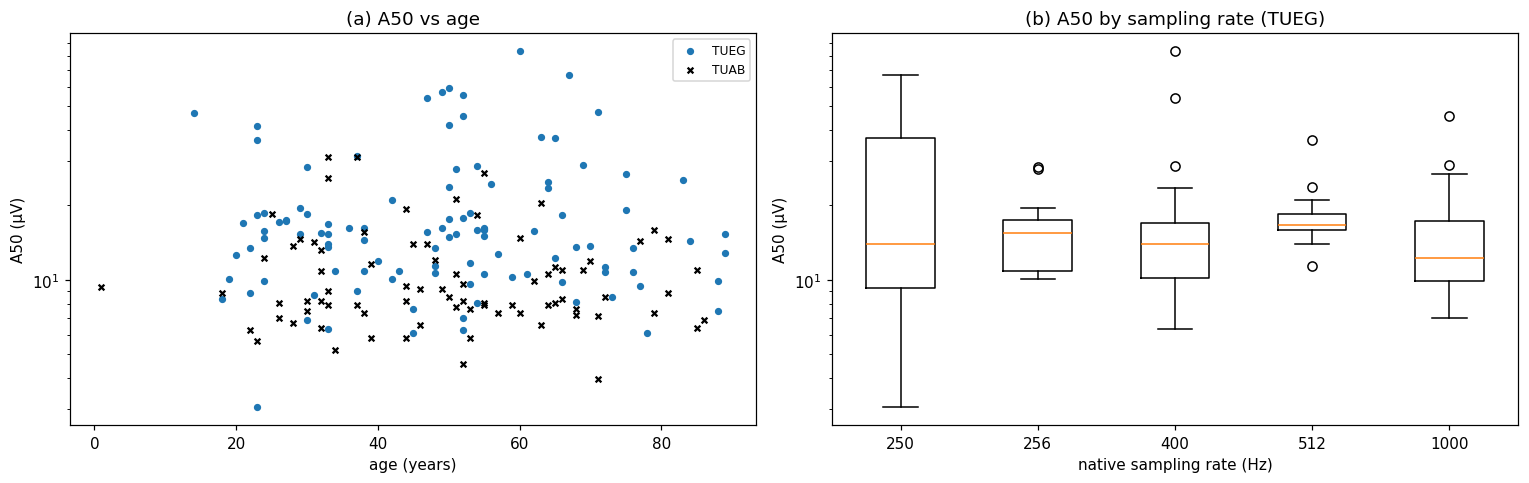

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ax.scatter(eg.age, eg.median_abs_uv, s=14, label="TUEG")
ax.scatter(ab.age, ab.median_abs_uv, marker="x", c="k", s=14, label="TUAB")
ax.set(title="A50 vs age", xlabel="age (years)", ylabel="A50 (µV)", yscale="log")
ax.legend(fontsize=8)
ax = axes[1]
sfs = sorted(eg.sfreq.unique())
ax.boxplot([eg.loc[eg.sfreq == s, "median_abs_uv"] for s in sfs], tick_labels=[f"{s:g}" for s in sfs])
ax.set(title="A50 by sampling rate (TUEG)", xlabel="native sampling rate (Hz)", ylabel="A50 (µV)",
       yscale="log")
panel_labels(axes)
assert_max_columns(fig)
plt.tight_layout(); plt.show()

No recording in the sample clips or has a flat channel (Table 7.1), so integrity filtering is
a corpus-level concern (missing channels, very short files; corpus index), not a per-sample
one. Amplitude is a different matter: TUEG's typical amplitude is markedly higher than TUAB's
(Table 7.1) — TUEG is not curated to routine recordings the way TUAB is — and it varies between
sampling-rate groups (Figure 7.1(b)), i.e. between equipment generations. In this sample
$A_{50}$ shows no clear trend with age (Figure 7.1(a)), so scale is mainly a corpus/equipment
difference here. LaBraM feeds the model $x/100$ (fixed scaling, `labram/train/train_finetune.py`),
which keeps both. Per-patch z-scoring (`labram_plus.z_score`, Section 9 of
`notebooks/tuab_data_preparation.ipynb`) removes absolute scale entirely; common average
reference (`labram_plus.common_average_reference`, on in the brain-age config) removes the
reference-dependent part shared across channels. Which of the two to use for TUEG is an
empirical question for the training experiments (Section 9).

## 8. Removing the line without a hole

A notch filter removes a band around 60 Hz whether or not there is interference in it: on a
recording without a line it cuts a hole into genuine EEG (the dips in Figure 5.1). Two
alternatives remove only the interference.

**Sinusoid fitting** (MNE `notch_filter(method="spectrum_fit")`, the approach of EEGLAB's
CleanLine): in sliding 10 s windows, a 60 Hz sinusoid is estimated by multitaper regression and
subtracted,

$$
\hat x(t) = x(t) - \hat a \cos(2\pi\, 60\, t) - \hat b \sin(2\pi\, 60\, t)
\tag{8.1}
$$

where $\hat a, \hat b$ (µV) are the window's fitted amplitudes, kept only when a multitaper F-test
finds the line significant.

**Spectrum interpolation** (Leske & Dalal 2019; `preprocessing_qc.py::spectrum_interpolate`):
the short-time Fourier transform $Z(f, \tau)$ with 10 s Hann windows and 50% overlap is modified
in the band $|f - 60| \le h$ as

$$
Z'(f, \tau) = \Big(\operatorname{mean}_{h < |f' - 60| \le h + 3} \lvert Z(f', \tau)\rvert\Big)\,
e^{\,i \angle Z(f, \tau)}, \qquad |f - 60| \le h,
\tag{8.2}
$$

i.e. the magnitude in the band is set to the mean magnitude of the 3 Hz on either side and the
phase is kept; the inverse transform gives the cleaned signal. $h$ = 1.5 Hz. Away from the band
the transform is an exact round trip.

Both are compared with the 60 Hz notch on two subsets of the sample: recordings **with a strong
line** (raw $\mathrm{LNP}_{60} > 10$ dB), where the question is how much of the line is left, and
**clean** recordings (raw $|\mathrm{LNP}_{60}| < 1$ dB), where the question is how deep a hole the
method cuts. Table 8.1 gives the numbers, Figure 8.1 the spectra.

### Table 8.1. Line left and hole cut by each line-removal method (after processing)

$\mathrm{LNP}_{60}$ (dB, Eq. 3.2) of the 200 Hz output after band-pass, the line-removal method and resampling. Strong-line recordings (raw $\mathrm{LNP}_{60} > 10$ dB): median and maximum line left (lower is better, 0 dB = no line). Clean recordings (raw $|\mathrm{LNP}_{60}| < 1$ dB): median $\mathrm{LNP}_{60}$, where a negative value is the hole the method cuts (closer to 0 is better). `n` recordings per subset; TUEG + TUAB.

In [14]:
strong = df[df.raw_lnp_60 > 10]
clean = df[df.raw_lnp_60.abs() < 1]
methods = [(L, "none (LaBraM, 50 Hz notch)"), (N60, "60 Hz notch"),
           ("60 Hz sinusoid fit", "60 Hz sinusoid fit (Eq. 8.1)"),
           ("60 Hz spectrum interpolation", "60 Hz spectrum interpolation (Eq. 8.2)")]
t81 = pd.DataFrame([{"method": label,
                     "strong: median left (dB)": strong[f"{k}|lnp_60"].median(),
                     "strong: max left (dB)": strong[f"{k}|lnp_60"].max(),
                     "clean: median (dB)": clean[f"{k}|lnp_60"].median(),
                     "clean: min (dB)": clean[f"{k}|lnp_60"].min()}
                    for k, label in methods]).set_index("method")
t81["n strong / clean"] = f"{len(strong)} / {len(clean)}"
numbered_table(t81, "8.1", "Line left and hole cut by each line-removal method", precision=1)

,strong: median left (dB),strong: max left (dB),clean: median (dB),clean: min (dB),n strong / clean
method,,,,,
"none (LaBraM, 50 Hz notch)",20.0,48.0,0.4,-1.0,48 / 45
60 Hz notch,-4.8,7.4,-5.6,-6.9,48 / 45
60 Hz sinusoid fit (Eq. 8.1),2.0,26.6,-1.3,-2.7,48 / 45
60 Hz spectrum interpolation (Eq. 8.2),-1.6,1.5,-1.3,-1.8,48 / 45


### Figure 8.1. Spectrum around 60 Hz after each line-removal method

Mean over recordings of $\log_{10} P(f)$ (µV²/Hz, Eq. 3.1) of the 200 Hz output after processing,
50–70 Hz, one line per method of Table 8.1: (a) TUEG and (b) TUAB recordings with a strong line
(raw $\mathrm{LNP}_{60} > 10$ dB); (c) TUEG and (d) TUAB clean recordings (raw
$|\mathrm{LNP}_{60}| < 1$ dB). $n$ in each panel title. A good method is flat at 60 Hz in all four
panels: no peak in (a, b), no dip in (c, d).

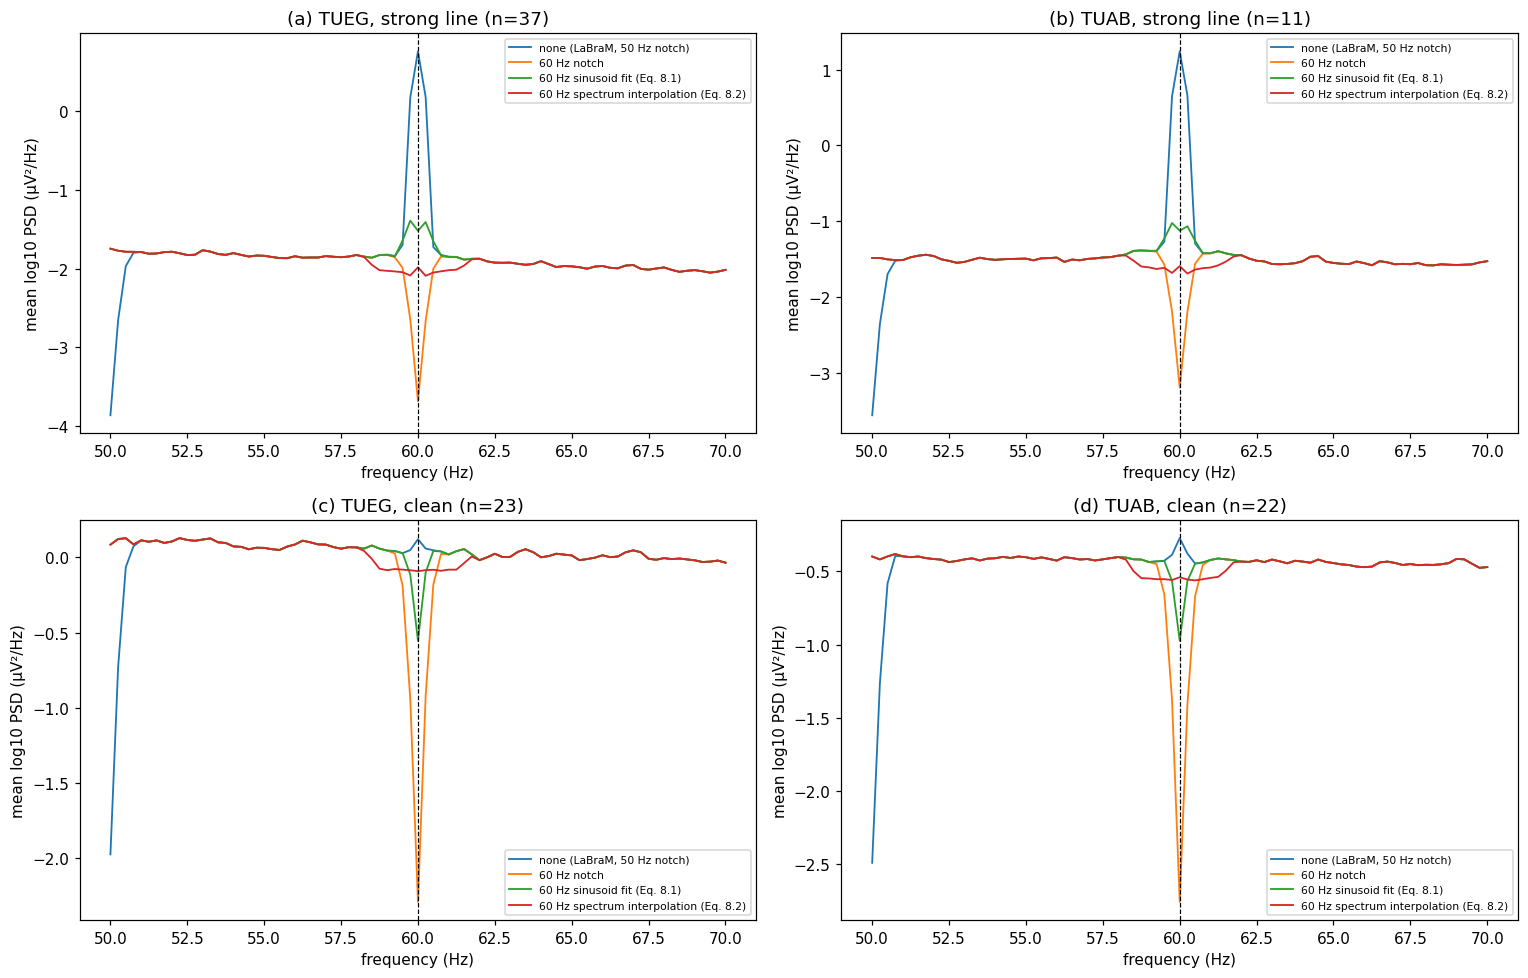

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (subset, label) in enumerate([(strong, "strong line"), (clean, "clean")]):
    for ax, group in zip(axes[row], ["TUEG", "TUAB"]):
        sub = subset[subset.group == group]
        for k, name in methods:
            f, y = mean_log_psd(sub.stem, f"{k}|psd", 50, 70)
            ax.plot(f, y, label=name, lw=1.2)
        ax.axvline(60, color="k", ls="--", lw=0.8)
        ax.set(title=f"{group}, {label} (n={len(sub)})", xlabel="frequency (Hz)",
               ylabel="mean log10 PSD (µV²/Hz)")
        ax.legend(fontsize=7)
panel_labels(axes)
assert_max_columns(fig)
plt.tight_layout(); plt.show()

**Spectrum interpolation removes the line best and cuts no meaningful hole.** On the
strong-line recordings it leaves no line at all (Table 8.1: median about −1.6 dB, worst case
1.5 dB — better than the notch's worst case of 7.4 dB, whose fixed narrow band misses lines that
are broader than it), and on clean recordings it lowers the 60 Hz band by only about 1 dB, against
a hole of about 5.6 dB from the notch (Figure 8.1(c, d)). Sinusoid fitting sits in between: on
clean recordings it still cuts a narrow dip exactly at 60 Hz (shallower than the notch's, Figure
8.1(c, d)), and on strong-line recordings it misses part of the line (worst case above 25 dB,
Figure 8.1(a, b)) — TUH's line drifts in amplitude within the 10 s fitting window, so a single
stationary sinusoid does not describe it. After interpolation the 60 Hz region is nearly flat in
all four panels of Figure 8.1: only a shallow plateau of about 1 dB remains across the ±1.5 Hz
band, while the notch leaves a deep dip in every cohort.

## 9. Conclusions and the recommended TUH protocol

1. **Mains: remove 60 Hz, not 50 Hz — by spectrum interpolation.** No recording has 50 Hz
   interference (Table 4.1); about half have a 60 Hz line whose strength depends on the equipment
   generation, which is itself tied to recording year and patient age at group level (Tables 2.1,
   6.2), though not to age recording by recording (Table 6.1). The LaBraM protocol passes this line
   to the model unchanged (Table 5.1, Figure 5.1(a, c)). Spectrum interpolation (Eq. 8.2,
   $h$ = 1.5 Hz) removes it from every recording without the hole a notch cuts (Table 8.1,
   Figure 8.1); a 60 Hz notch is the fallback. To be confirmed by a TUAB training comparison
   (notch vs interpolation) before the TUEG conversion.
2. **Keep the 0.1–75 Hz band-pass and 200 Hz resampling.** They cause no aliasing at any native
   rate from 250 to 1000 Hz (alias probes in Tables 4.1 and 5.1) and match what the pre-trained
   LaBraM weights expect. A 45 Hz low-pass is not needed once the line is removed.
3. **Units are consistent** (all µV, Table 2.2); the header prefiltering field is uninformative,
   so per-recording QC must come from the signal.
4. **Amplitude differs by corpus and equipment** (Table 7.1, Figure 7.1); keep CAR, and compare
   per-patch z-scoring against fixed scaling in the first TUEG experiments.
5. **Consistency:** TUAB must be preprocessed with exactly the same recipe as TUEG when the two
   are mixed. For the TUAB benchmark (comparison with published numbers) the original 50 Hz
   recipe stays available.

Table 9.1 summarises the recommendation.

### Table 9.1. LaBraM protocol vs the recommended TUH protocol

One row per preprocessing step; `evidence` names the table or figure that supports the change.

In [16]:
t91 = pd.DataFrame([
    ("channels", "23 referential, exact set required", "23 referential, missing ones zero-filled + channel_mask", "corpus index (23% of TUEG recordings miss ≥1 channel)"),
    ("band-pass", "0.1–75 Hz", "0.1–75 Hz (unchanged)", "Tables 4.1, 5.1"),
    ("mains removal", "50 Hz notch", "60 Hz spectrum interpolation (±1.5 Hz); 60 Hz notch as fallback", "Tables 4.1, 5.1, 6.2, 8.1; Figures 5.1, 8.1"),
    ("resample", "200 Hz", "200 Hz (unchanged)", "Table 5.1 (no aliasing)"),
    ("units / scale", "µV, model input x/100", "µV; CAR on; z-score vs fixed scaling tested", "Table 7.1, Figure 7.1"),
    ("TUAB", "as published", "re-made with the TUH recipe when mixed with TUEG; published recipe kept for the benchmark", "Section 9, item 5"),
], columns=["step", "LaBraM (TUAB papers)", "recommended for TUH", "evidence"]).set_index("step")
numbered_table(t91, "9.1", "LaBraM protocol vs the recommended TUH protocol")

,LaBraM (TUAB papers),recommended for TUH,evidence
step,,,
channels,"23 referential, exact set required","23 referential, missing ones zero-filled + channel_mask",corpus index (23% of TUEG recordings miss ≥1 channel)
band-pass,0.1–75 Hz,0.1–75 Hz (unchanged),"Tables 4.1, 5.1"
mains removal,50 Hz notch,60 Hz spectrum interpolation (±1.5 Hz); 60 Hz notch as fallback,"Tables 4.1, 5.1, 6.2, 8.1; Figures 5.1, 8.1"
resample,200 Hz,200 Hz (unchanged),Table 5.1 (no aliasing)
units / scale,"µV, model input x/100",µV; CAR on; z-score vs fixed scaling tested,"Table 7.1, Figure 7.1"
TUAB,as published,re-made with the TUH recipe when mixed with TUEG; published recipe kept for the benchmark,"Section 9, item 5"
